In [1]:
import sys
sys.path.append('..')

In [2]:
from src import utils
import matplotlib.pyplot as plt
from types import SimpleNamespace
from src import SV_configs

In [3]:
from matplotlib.lines import Line2D
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [4]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'aligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 15,
    'num_samples' : 100,
    'num_epochs' : 20000,
    'lr' : 0.1,
    'initialization_scale' : 1e-1,
    'input_size' : 6,
    'hidden_size' : 6,
    'output_size' : 6,
    'S_config': ['constant','inverse_exponential','exponential','constant','inverse_exponential','exponential'],
    'delta' : [0.2,1,1,1.1,1,1], 
    'lambda_0' : [1,0.7,0.7,1,1.1,1.1],
    'S_T' : [1,1,1,1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01,0.01,0.01,0.01,0.01],
    'in_mode_init' : [0.1,0.1,0.1,0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1],
    'rec_mode_init': [0.1,0.1,0.1,0.1,0.1,0.1],
    'num_SV' : 6,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': False,
    'eigenspace_dynamics': False
}
args = SimpleNamespace(**args)

In [5]:
args.S = SV_configs.create_SV_trajectories(args)

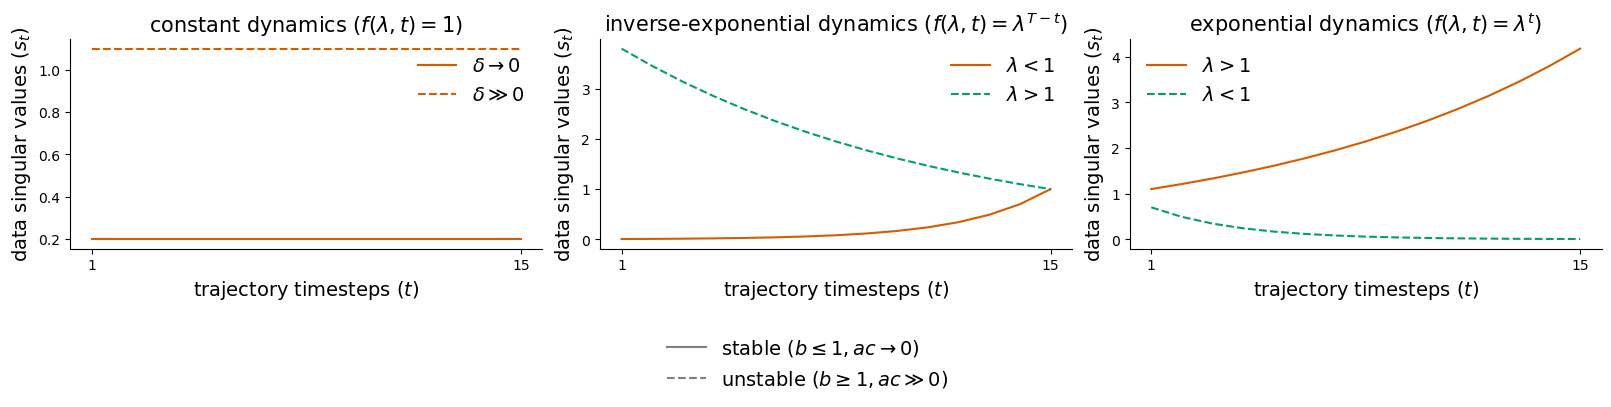

In [6]:
fig = plt.figure(figsize=(16,3), layout='constrained') 
mosaic = """
abc
"""
axd = fig.subplot_mosaic(mosaic)

ax = axd['a']
ax.plot(range(1,args.trajectory_length+1), args.S[:,0,0], color=blind_colors[0], label=r'$\delta \rightarrow 0$')
ax.plot(range(1,args.trajectory_length+1), args.S[:,3,3], ls='dashed', color=blind_colors[0], label=r'$\delta \gg 0$')
ax.set_xlabel(r'trajectory timesteps ($t$)', fontsize=14)
ax.set_ylabel(r'data singular values ($s_t$)',fontsize=14)
ax.legend(frameon=False, fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks([1, 15])
ax.set_title(r'constant dynamics ($f(\lambda,t)=1$)',fontsize=15)

ax = axd['b']
ax.plot(range(1,args.trajectory_length+1), args.S[:,1,1], color=blind_colors[0], label=r'$\lambda < 1$')
ax.plot(range(1,args.trajectory_length+1), args.S[:,4,4], ls='dashed', color=blind_colors[2], label=r'$\lambda > 1$')
ax.set_xlabel(r'trajectory timesteps ($t$)', fontsize=14)
ax.set_ylabel(r'data singular values ($s_t$)', fontsize=14)
ax.legend(frameon=False, fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks([1, 15])
ax.set_title(r'inverse-exponential dynamics ($f(\lambda,t)=\lambda^{T-t}$)',fontsize=15)

ax = axd['c']
ax.plot(range(1,args.trajectory_length+1), args.S[:,5,5], color=blind_colors[0], label=r'$\lambda > 1$')
ax.plot(range(1,args.trajectory_length+1), args.S[:,2,2], ls='dashed', color=blind_colors[2], label=r'$\lambda < 1$')
ax.set_xlabel(r'trajectory timesteps ($t$)', fontsize=14)
ax.set_ylabel(r'data singular values ($s_t$)',fontsize=14)
ax.legend(frameon=False, fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks([1, 15])
ax.set_title(r'exponential dynamics ($f(\lambda,t)=\lambda^t$)',fontsize=15)


handles, labels = plt.gca().get_legend_handles_labels()
line_1 = Line2D([0], [0], label=r'stable ($b \leq 1, ac \rightarrow 0$)', color='gray')
line_2 = Line2D([0], [0], label=r'unstable ($b \geq 1, ac \gg 0$)', color='gray', ls='dashed')
handles = [line_1, line_2]
fig.legend(frameon=False, handles=handles, bbox_to_anchor=(0.6, -0.05), fontsize=14)#, bbox_to_anchor=(0.65, -0.05))
# fig.savefig('paper_figs/stability_extrapolation_6.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/stability_extrapolation_6.png', dpi=300, transparent=True, bbox_inches='tight')